# MLOps Assignment: Predictive Maintenance Classification
### Starter Notebook

**Domain:** Industrial IoT / Manufacturing
**Task:** Multi-class failure type prediction
**Tools:** Pandera ? MLflow ? Optuna ? Evidently ? SHAP

---

## Business Context

A heavy-equipment manufacturer runs 10,000+ machines on the shop floor.
Each machine continuously streams six sensor readings. When a machine fails,
production halts at a cost of 8-15 lakh per hour of downtime.

Your job is to build a full MLOps pipeline that:
1. Validates incoming sensor data before it enters the pipeline (Pandera)
2. Trains and tracks a multi-class failure classifier (MLflow)
3. Tunes hyperparameters and registers the best model (Optuna + MLflow Registry)
4. Monitors the deployed model for distributional shift (Evidently)
5. Explains why the model predicts a specific failure type (SHAP)

**Files provided:**
- `data/train.csv`: 6,993 labelled sensor readings (historical baseline)
- `data/current.csv`: 1,499 readings from the current stable production batch
- `data/stress.csv`: 1,499 readings from a heavy-load production period

**Failure classes:**

| Code | Name | Description |
|------|------|-------------|
| 0 | No Failure | Machine operating normally |
| 1 | TWF | Tool Wear Failure |
| 2 | HDF | Heat Dissipation Failure |
| 3 | PWF | Power Failure |
| 4 | OSF | Overstrain Failure |


> **Visual anchor:** Use the generated `eda_distributions.png` early (Section 1.3) to ground your expectations before drift and SHAP interpretation.

> **Stress-batch goal:** Diagnose *why* the model is stale under shifted operating conditions, not to force perfect predictions on `stress.csv`.

> **Submission:** Submit this notebook (`.ipynb`) with all cells executed.

> **Do not change the section structure or remove any markdown cells.**

## **1. Data Loading, Schema Validation & EDA** <font color=red>[15 marks]</font>

### **1.1** <font color=red>[3 marks]</font> Load the datasets

Load `train.csv`, `current.csv`, and `stress.csv` from the `data/` folder.
Print the shape of each and display the first 5 rows of the training set.


In [3]:

import warnings
warnings.filterwarnings("ignore")

import os
os.environ["DISABLE_PANDERA_IMPORT_WARNING"] = "True"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
train = pd.read_csv("data/train.csv")
current = pd.read_csv("data/current.csv")
stress = pd.read_csv("data/stress.csv")

# Display dataset shapes
print("Train shape:", train.shape)
print("Current shape:", current.shape)
print("Stress shape:", stress.shape)

# Class names
CLASS_NAMES = {
    0: "No Failure",
    1: "TWF",
    2: "HDF",
    3: "PWF",
    4: "OSF"
}

# Display first five training records
display(train.head())


Train shape: (6993, 7)
Current shape: (1499, 7)
Stress shape: (1499, 7)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Failure_Type
0,L,302.5,311.1,1499,38.8,135,0
1,L,297.3,308.4,1469,46.7,65,0
2,L,297.3,308.5,1504,42.0,142,0
3,L,299.6,309.5,1803,27.7,159,0
4,L,301.1,311.1,1387,53.1,188,0


### **1.2** <font color=red>[5 marks]</font> Define and apply a Pandera schema

Define a `DataFrameSchema` enforcing the domain constraints below.
Validate `train` and `current` (must pass). Validate `stress` with `lazy=True`.

| Column | Type | Constraint |
|--------|------|------------|
| Type | str | one of L, M, H |
| Air temperature | float | [295.0, 305.0] K |
| Process temperature | float | [305.0, 315.0] K |
| Rotational speed | int64 | [1000, 2900] rpm |
| Torque | float | [3.0, 80.0] Nm |
| Tool wear | int64 | [0, 253] min |
| Failure_Type | int64 | 0, 1, 2, 3, 4 |


> `stress.csv` may still pass schema validation. That is fine: It is designed to be valid but drifted.

> **Hint:** Valid data can still be statistically unusual. Before Section 3, compare the mean of `Rotational speed` in `current` vs `stress`.

In [13]:

import pandera as pa
from pandera import Column, DataFrameSchema, Check

# Define schema with domain constraints
schema = DataFrameSchema({
    "Type": Column(str, Check.isin(["L", "M", "H"])),

    "Air temperature": Column(
        float, Check.in_range(295.0, 305.0)
    ),

    "Process temperature": Column(
        float, Check.in_range(305.0, 315.0)
    ),

    "Rotational speed": Column(
        "int64", Check.in_range(1000, 2900)
    ),

    "Torque": Column(
        float, Check.in_range(3.0, 80.0)
    ),

    "Tool wear": Column(
        "int64", Check.in_range(0, 253)
    ),

    "Failure_Type": Column(
        "int64", Check.isin([0, 1, 2, 3, 4])
    )
})

# Fix integer data types before validation
def fix_dtypes(df):
    df = df.copy()
    df["Rotational speed"] = df["Rotational speed"].astype("int64")
    df["Tool wear"] = df["Tool wear"].astype("int64")
    df["Failure_Type"] = df["Failure_Type"].astype("int64")
    return df

train = fix_dtypes(train)
current = fix_dtypes(current)
stress = fix_dtypes(stress)

# Validate all three datasets
for name, df in [
    ("Train", train),
    ("Current", current),
    ("Stress", stress)
]:
    try:
        schema.validate(df, lazy=True)
        print(f"{name}: Schema validation PASSED")
    except pa.errors.SchemaErrors as e:
        print(f"{name}: Schema validation FAILED")
        display(e.failure_cases)


Train: Schema validation PASSED
Current: Schema validation PASSED
Stress: Schema validation PASSED


### **1.3** <font color=red>[4 marks]</font> Exploratory Data Analysis

1. Print the class distribution of `Failure_Type`. Is it balanced?
2. Plot the distribution of `Torque` and `Tool wear` split by failure class (failures only).
3. Print the `Type` (L/M/H) distribution.


Class Distribution:
Failure_Type
0    6762
1      30
2      76
3      56
4      69
Name: count, dtype: int64

Class Distribution (%):
Failure_Type
0    96.70
1     0.43
2     1.09
3     0.80
4     0.99
Name: proportion, dtype: float64


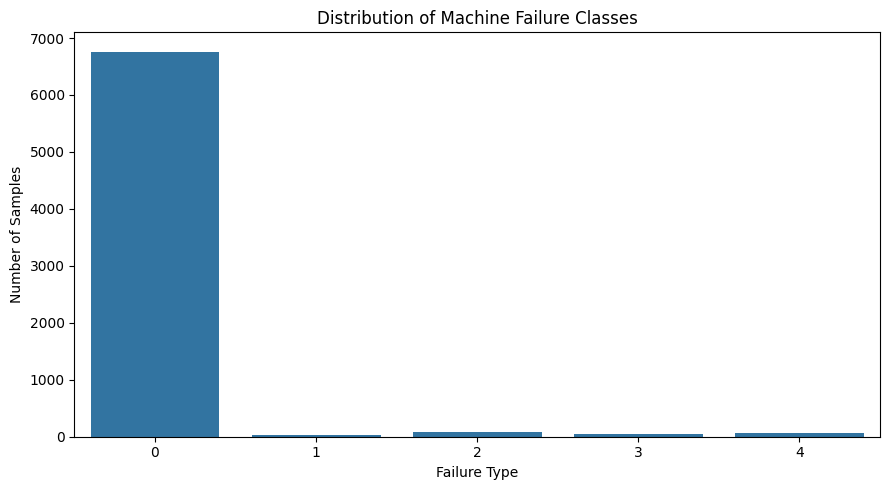

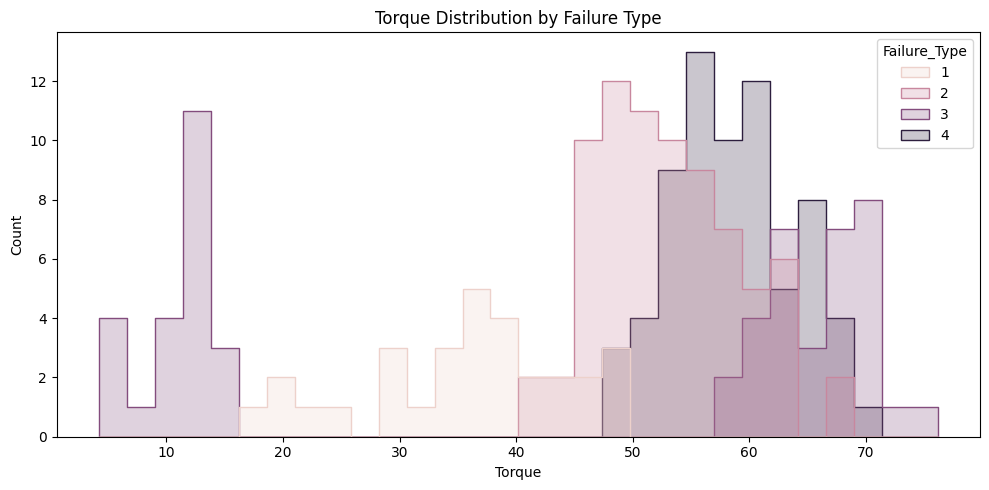

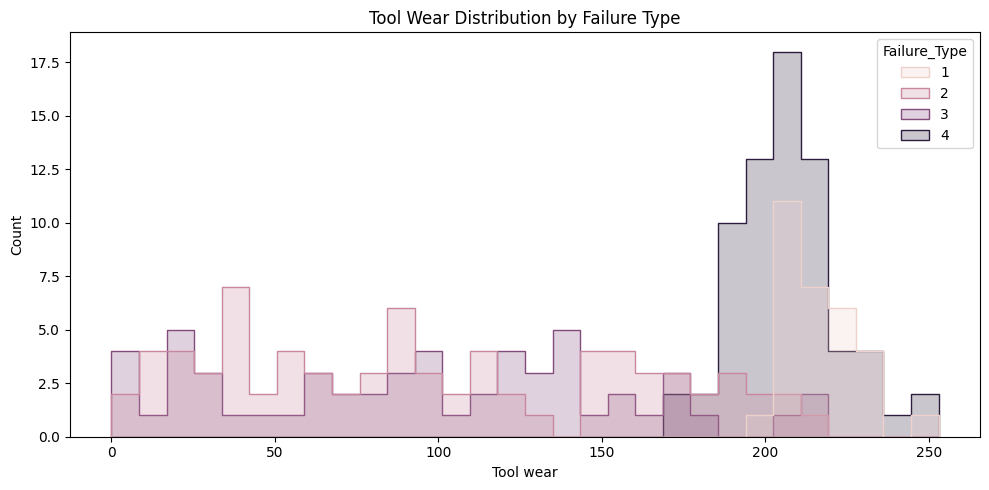


Machine Type Distribution:
Type
L    4213
M    2074
H     706
Name: count, dtype: int64

Machine Type Distribution (%):
Type
L    60.25
M    29.66
H    10.10
Name: proportion, dtype: float64


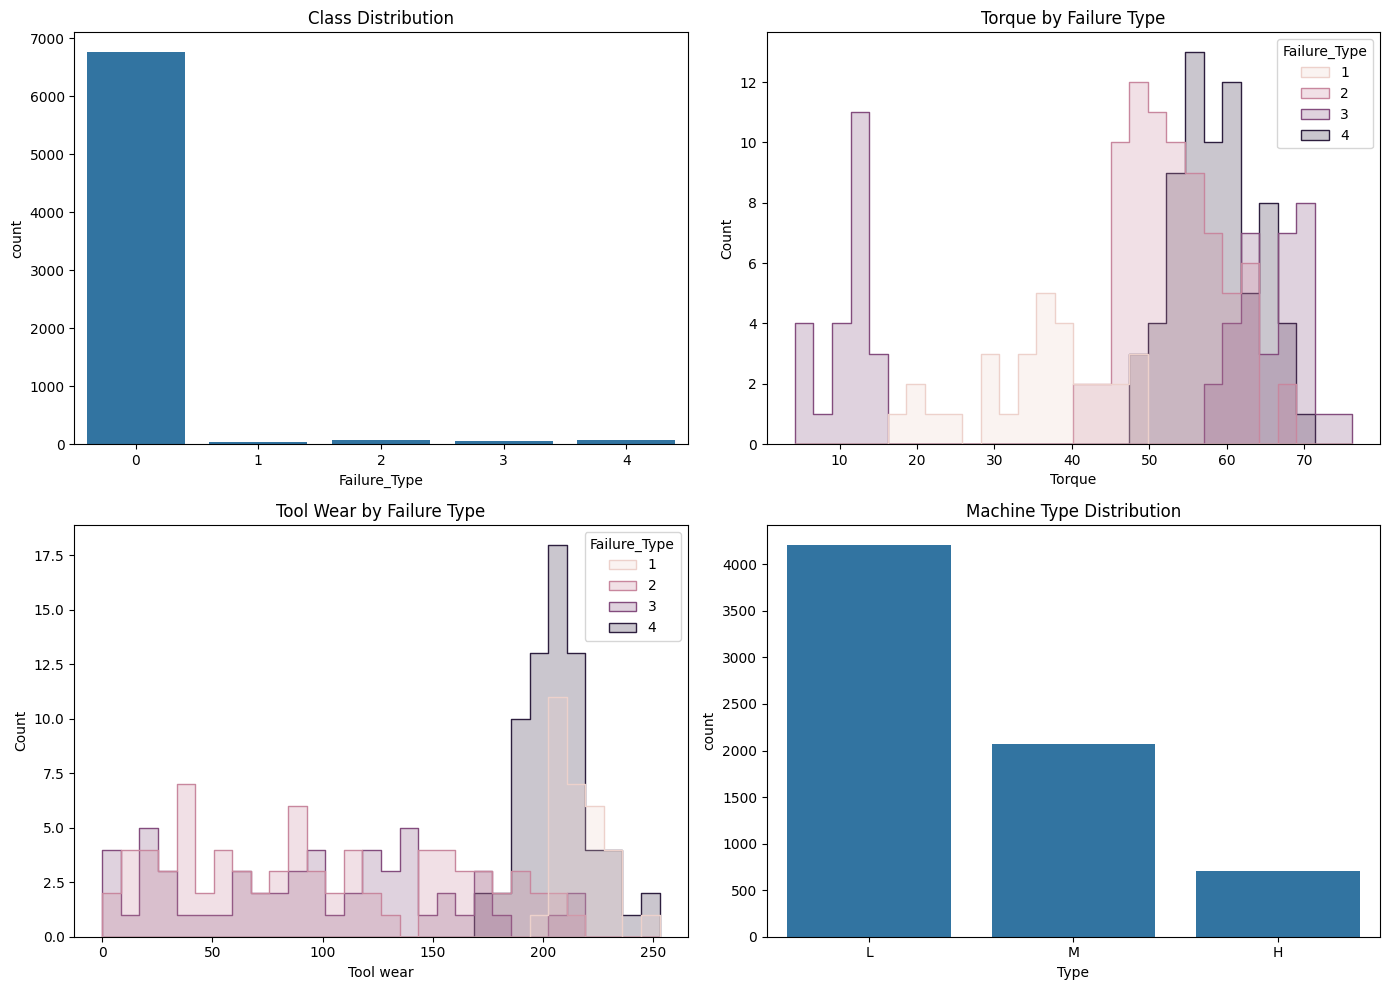


EDA plot saved as eda_distributions.png


In [14]:


# 1. Class distribution
class_counts = train["Failure_Type"].value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

print("\nClass Distribution (%):")
print((train["Failure_Type"].value_counts(
    normalize=True
).sort_index() * 100).round(2))

# Plot class distribution
plt.figure(figsize=(9, 5))
sns.countplot(
    data=train,
    x="Failure_Type",
    order=[0, 1, 2, 3, 4]
)
plt.title("Distribution of Machine Failure Classes")
plt.xlabel("Failure Type")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

# 2. Filter failure records only
failures = train[train["Failure_Type"] != 0].copy()

# 3. Torque distribution by failure type
plt.figure(figsize=(10, 5))
sns.histplot(
    data=failures,
    x="Torque",
    hue="Failure_Type",
    bins=30,
    element="step",
    common_norm=False
)
plt.title("Torque Distribution by Failure Type")
plt.tight_layout()
plt.show()

# 4. Tool wear distribution by failure type
plt.figure(figsize=(10, 5))
sns.histplot(
    data=failures,
    x="Tool wear",
    hue="Failure_Type",
    bins=30,
    element="step",
    common_norm=False
)
plt.title("Tool Wear Distribution by Failure Type")
plt.tight_layout()
plt.show()

# 5. Machine quality distribution
print("\nMachine Type Distribution:")
print(train["Type"].value_counts())

print("\nMachine Type Distribution (%):")
print(
    (train["Type"].value_counts(normalize=True) * 100).round(2)
)

# 6. Save all required EDA plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(
    data=train, x="Failure_Type",
    order=[0, 1, 2, 3, 4], ax=axes[0, 0]
)
axes[0, 0].set_title("Class Distribution")

sns.histplot(
    data=failures, x="Torque",
    hue="Failure_Type", bins=30,
    element="step", ax=axes[0, 1]
)
axes[0, 1].set_title("Torque by Failure Type")

sns.histplot(
    data=failures, x="Tool wear",
    hue="Failure_Type", bins=30,
    element="step", ax=axes[1, 0]
)
axes[1, 0].set_title("Tool Wear by Failure Type")

sns.countplot(
    data=train, x="Type",
    order=["L", "M", "H"], ax=axes[1, 1]
)
axes[1, 1].set_title("Machine Type Distribution")

plt.tight_layout()
plt.savefig("eda_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nEDA plot saved as eda_distributions.png")


### EDA Observations

The training dataset contains 6,993 observations and exhibits severe class imbalance. The No Failure class dominates with 6,762 records (96.70%), while failure classes collectively represent only 3.30%.

Tool Wear Failure (TWF) is the rarest class, with only 30 samples (0.43%). This scarcity may make it difficult for machine learning models to learn reliable TWF patterns.

Machine type L represents the largest proportion of observations (60.25%), followed by M (29.66%) and H (10.10%).

Due to the severe target imbalance, macro F1-score will be used as the primary model-selection metric. SMOTE will be applied only to the training split to reduce imbalance without introducing validation leakage.

### **1.4** <font color=red>[3 marks]</font> Feature Engineering

Compute the following derived features for all three datasets:

**Mechanical power** (Watts):
$$P = \text{Torque} \times \frac{\text{Rotational speed} \times 2\pi}{60}$$

**Temperature differential**:
$$\Delta T = \text{Process temperature} - \text{Air temperature}$$

Print the mean of each new feature grouped by `Failure_Type`.


In [15]:

def engineer_features(df):
    df = df.copy()

    # Mechanical power in Watts
    df["Power_W"] = (
        2 * np.pi *
        df["Rotational speed"] *
        df["Torque"] / 60
    )

    # Process-to-air temperature difference
    df["Temp_diff"] = (
        df["Process temperature"] -
        df["Air temperature"]
    )

    return df


# Apply to all three datasets
train = engineer_features(train)
current = engineer_features(current)
stress = engineer_features(stress)

# Verify shapes
print("Train shape:", train.shape)
print("Current shape:", current.shape)
print("Stress shape:", stress.shape)

# Check engineered features
print("\nEngineered Features Sample:")
display(train[[
    "Rotational speed",
    "Torque",
    "Power_W",
    "Air temperature",
    "Process temperature",
    "Temp_diff"
]].head())

# Grouped statistics by failure class
print("\nMean Engineered Features by Failure Type:")
grouped_stats = train.groupby("Failure_Type")[
    ["Power_W", "Temp_diff"]
].mean().round(2)

display(grouped_stats)

# Verify no missing values
print("\nMissing Values in Engineered Features:")
print(train[["Power_W", "Temp_diff"]].isnull().sum())

# Check all datasets
for name, df in [
    ("Train", train),
    ("Current", current),
    ("Stress", stress)
]:
    assert {"Power_W", "Temp_diff"}.issubset(df.columns)
    assert df[["Power_W", "Temp_diff"]].notna().all().all()
    print(f"{name}: Feature engineering PASSED")


Train shape: (6993, 9)
Current shape: (1499, 9)
Stress shape: (1499, 9)

Engineered Features Sample:


,Rotational speed,Torque,Power_W,Air temperature,Process temperature,Temp_diff
0,1499,38.8,6090.626621,302.5,311.1,8.6
1,1469,46.7,7184.016057,297.3,308.4,11.1
2,1504,42.0,6614.937491,297.3,308.5,11.2
3,1803,27.7,5230.029202,299.6,309.5,9.9
4,1387,53.1,7712.578549,301.1,311.1,10.0



Mean Engineered Features by Failure Type:


,Power_W,Temp_diff
Failure_Type,,
0,6248.24,10.01
1,5763.09,9.97
2,7403.55,8.23
3,6664.38,9.82
4,8216.07,10.07



Missing Values in Engineered Features:
Power_W      0
Temp_diff    0
dtype: int64
Train: Feature engineering PASSED
Current: Feature engineering PASSED
Stress: Feature engineering PASSED


### Feature Engineering Observations

Two physically meaningful features, `Power_W` and `Temp_diff`, were engineered successfully for all three datasets. Each dataset now contains nine columns, and neither engineered feature contains missing values.

**Key observations:**

1. **Heat Dissipation Failure (HDF):** The mean temperature difference is 8.23 K, compared with 10.01 K for normal operation. This suggests that reduced process-to-air temperature differences may be associated with heat dissipation failures.

2. **Overstrain Failure (OSF):** The highest mean mechanical power (8,216.07 W) occurs in the OSF class, compared with 6,248.24 W for normal operation. This suggests a potential association between high mechanical loading and overstrain failures.

3. **Power Failure (PWF):** The mean power is 6,664.38 W. Further analysis of the full power distribution is necessary because mean values may conceal extreme operating conditions.

4. **Tool Wear Failure (TWF):** The mean power is 5,763.09 W. However, only 30 TWF observations are available, limiting confidence in the observed pattern.

**Conclusion:** Both engineered features provide physically interpretable information that may improve failure classification. Their actual predictive contributions will be evaluated during model training and SHAP analysis.

## **2. Experiment Tracking & Model Selection** <font color=red>[15 marks]</font>

### **2.1** <font color=red>[2 marks]</font> Setup: features, split, SMOTE

Use the features below. Apply a stratified 80/20 train-val split (random_state=42).
Apply SMOTE to the training split only. Print the post-SMOTE class distribution.

```
FEATURES = ['Type_enc', 'Air temperature', 'Process temperature',
            'Rotational speed', 'Torque', 'Tool wear', 'Power_W', 'Temp_diff']
```

> In a markdown cell below the code, explain in 2–3 sentences why SMOTE is applied
> only to the training split and not the validation set.


In [21]:


from sklearn.preprocessing import LabelEncoder

# Encode machine Type
le = LabelEncoder()

# Fit encoder only on training data
train["Type_enc"] = le.fit_transform(train["Type"])

# Reuse the fitted encoder
current["Type_enc"] = le.transform(current["Type"])
stress["Type_enc"] = le.transform(stress["Type"])

# Display category mappings
print("Type Encoding Mapping:")
for label, encoded in zip(
    le.classes_,
    le.transform(le.classes_)
):
    print(f"{label} -> {encoded}")

# Define input features
FEATURES = [
    "Type_enc",
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear",
    "Power_W",
    "Temp_diff"
]

# Create feature matrix and target vector
X = train[FEATURES].copy()
y = train["Failure_Type"].copy()

# Verify shapes
print("\nFeature Matrix Shape:", X.shape)
print("Target Vector Shape:", y.shape)

# Verify target classes
print("\nTarget Classes:", sorted(y.unique()))

# Check missing values
print("\nMissing Values in Features:")
print(X.isnull().sum())

print("\nSelected Features:")
print(FEATURES)



# STEP 2.1.2 - Stratified Train-Validation Split

from sklearn.model_selection import train_test_split

# Split dataset (80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Training Features:", X_train.shape)
print("Validation Features:", X_val.shape)

print("Training Target:", y_train.shape)
print("Validation Target:", y_val.shape)

# Class distribution in training set
print("\nTraining Class Distribution:")
print(y_train.value_counts().sort_index())

# Class distribution in validation set
print("\nValidation Class Distribution:")
print(y_val.value_counts().sort_index())

# Compare class percentages
comparison = pd.DataFrame({
    "Original (%)": y.value_counts(normalize=True).sort_index() * 100,
    "Training (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Validation (%)": y_val.value_counts(normalize=True).sort_index() * 100
}).round(2)

print("\nClass Distribution Comparison:")
display(comparison)

# Verify no overlap between train and validation rows
overlap = set(X_train.index).intersection(set(X_val.index))

print("\nOverlapping Row Indices:", len(overlap))

assert len(overlap) == 0, "Data leakage detected!"

print("\nStratified Split PASSED")


# STEP 2.1.3 - Handle Class Imbalance with SMOTE

from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(
    random_state=42,
    k_neighbors=3
)

# Apply SMOTE only to training data
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

# Original training class distribution
print("Before SMOTE:")
print(y_train.value_counts().sort_index())

# Balanced training class distribution
print("\nAfter SMOTE:")
print(y_train_smote.value_counts().sort_index())

# Compare shapes
print("\nOriginal Training Shape:", X_train.shape)
print("SMOTE Training Shape:", X_train_smote.shape)

# Validation set remains unchanged
print("\nValidation Shape:", X_val.shape)

# Verify class balancing
counts = y_train_smote.value_counts()
assert counts.nunique() == 1, "SMOTE balancing failed!"

# Verify validation set was not modified
assert len(X_val) == 1399
assert len(y_val) == 1399

print("\nSMOTE Validation PASSED")




Type Encoding Mapping:
H -> 0
L -> 1
M -> 2

Feature Matrix Shape: (6993, 8)
Target Vector Shape: (6993,)

Target Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Missing Values in Features:
Type_enc               0
Air temperature        0
Process temperature    0
Rotational speed       0
Torque                 0
Tool wear              0
Power_W                0
Temp_diff              0
dtype: int64

Selected Features:
['Type_enc', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Power_W', 'Temp_diff']
Training Features: (5594, 8)
Validation Features: (1399, 8)
Training Target: (5594,)
Validation Target: (1399,)

Training Class Distribution:
Failure_Type
0    5409
1      24
2      61
3      45
4      55
Name: count, dtype: int64

Validation Class Distribution:
Failure_Type
0    1353
1       6
2      15
3      11
4      14
Name: count, dtype: int64

Class Distribution Comparison:


,Original (%),Training (%),Validation (%)
Failure_Type,,,
0,96.70,96.69,96.71
1,0.43,0.43,0.43
2,1.09,1.09,1.07
3,0.80,0.80,0.79
4,0.99,0.98,1.00



Overlapping Row Indices: 0

Stratified Split PASSED
Before SMOTE:
Failure_Type
0    5409
1      24
2      61
3      45
4      55
Name: count, dtype: int64

After SMOTE:
Failure_Type
0    5409
1    5409
2    5409
3    5409
4    5409
Name: count, dtype: int64

Original Training Shape: (5594, 8)
SMOTE Training Shape: (27045, 8)

Validation Shape: (1399, 8)

SMOTE Validation PASSED


*Your explanation here: why is SMOTE applied only on the training split?*

### Why is SMOTE applied only on the training split?

SMOTE (Synthetic Minority Oversampling Technique) is applied only to the training split to **prevent data leakage and ensure unbiased model evaluation**.

SMOTE generates synthetic samples for minority classes using their nearest neighbors. If SMOTE is applied before splitting the dataset, information from synthetic samples may be shared between the training and validation sets, resulting in overly optimistic performance metrics.

By applying SMOTE only to the training data:

1. **Prevents data leakage:** Synthetic samples are generated using training data only.
2. **Preserves realistic validation data:** The validation set retains the original class distribution, representing real-world machine failure conditions.
3. **Improves minority-class learning:** The model receives additional synthetic examples of rare failures such as TWF, HDF, PWF, and OSF.
4. **Ensures fair evaluation:** Macro F1-score is calculated on untouched validation data, providing a more reliable comparison between models.

For this assignment, SMOTE is configured with `k_neighbors=3` because the rarest failure class (TWF) contains only 30 original samples.

**Conclusion:** Applying SMOTE after the train-validation split helps address class imbalance while preventing data leakage and maintaining reliable model evaluation.

### **2.2** <font color=red>[8 marks]</font> Train and log 4 models with MLflow

Train and evaluate:
- Logistic Regression
- Random Forest (n_estimators=100)
- XGBoost (n_estimators=100)
- LightGBM (n_estimators=100)

MLflow experiment name: `PredMaint_ModelSelection`

For each run log: `model` (param), `macro_f1`, `weighted_f1`, `accuracy` (metrics),
and per-class F1 for all 5 classes. Print a comparison table. Pick the best model by macro F1.


In [ ]:
import mlflow
import mlflow.sklearn
from sklearn.metrics import f1_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('PredMaint_ModelSelection')

CLASS_LIST = [0, 1, 2, 3, 4]
results = {}

models_to_run = {
    'LogisticRegression': Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(max_iter=2000, random_state=42,
                                  class_weight='balanced'))
    ]),
    'RandomForest':       RandomForestClassifier(n_estimators=100, random_state=42,
                                                  class_weight='balanced'),
    'XGBoost':            XGBClassifier(n_estimators=100, random_state=42,
                                         eval_metric='mlogloss', verbosity=0),
    'LightGBM':           LGBMClassifier(n_estimators=100, random_state=42,
                                          class_weight='balanced', verbose=-1),
}

# TODO: For each model:
#   - Start an MLflow run
#   - Fit on X_res, y_res
#   - Predict on X_val
#   - Compute and log macro_f1, weighted_f1, accuracy, per-class F1
#   - Log the model artefact (use input_example=X_val.iloc[:5])

# TODO: Print comparison table
# TODO: Identify best model by macro F1


### **2.3** <font color=red>[5 marks]</font> Optuna tuning + MLflow Model Registry

Run an Optuna study (30 trials, `TPESampler(seed=42)`) tuning XGBoost hyperparameters.
Optimise for `macro_f1` on `X_val`.

MLflow experiment: `PredMaint_Optuna`

Register the best model as `PredMaint_XGBoost` and promote it to the `production` alias.
Print the improvement in macro F1 over the baseline XGBoost.


In [ ]:
import optuna
import joblib

optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_experiment('PredMaint_Optuna')

def objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'min_child_weight':  trial.suggest_float('min_child_weight', 1.0, 10.0),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma':             trial.suggest_float('gamma', 0.0, 2.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-8, 5.0, log=True),
        'random_state': 42, 'eval_metric': 'mlogloss', 'verbosity': 0,
    }
    # TODO: Train XGBoost model, return macro_f1 on X_val

study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=42))
# TODO: Run study.optimize

# TODO: Train final best model
# TODO: Log to MLflow, register as 'PredMaint_XGBoost', promote to production alias
# TODO: Save with joblib.dump


## **3. Drift Detection & Monitoring** <font color=red>[10 marks]</font>

> **Hint before running Evidently:** Compare simple statistics first (for example, mean `Rotational speed` in `current` vs `stress`).

> **Reminder:** Passing Pandera only means values are valid; it does **not** mean the batch is in-distribution.

> **Section objective:** Identify why the deployed model is stale on stress conditions.

### **3.1** <font color=red>[4 marks]</font> Evidently: current batch

Reference: `train[FEAT_COLS]` | Current: `current[FEAT_COLS]`

```
FEAT_COLS = ['Air temperature', 'Process temperature',
             'Rotational speed', 'Torque', 'Tool wear']
```

- Run `DataDriftPreset`
- Save HTML to `drift_current.html`
- Report: drift detected? How many features drifted?


In [ ]:
from evidently.legacy.report import Report
from evidently.legacy.metric_preset import DataDriftPreset

FEAT_COLS = ['Air temperature', 'Process temperature',
             'Rotational speed', 'Torque', 'Tool wear']

# TODO: Run Evidently on current batch, save drift_current.html, print summary


### **3.2** <font color=red>[4 marks]</font> Evidently: stress batch

- Repeat for `stress.csv`
- Use `ColumnDriftMetric` for individual feature scores
- Save as `drift_stress.html`
- Print a table: feature | drift detected | Wasserstein score | ref mean | current mean | delta.

Focus question: this section is about diagnosing *staleness risk* (what shifted and why), not "making stress predictions look good."

In [ ]:
from evidently.legacy.metrics.data_drift.dataset_drift_metric import DatasetDriftMetric
from evidently.legacy.metrics.data_drift.column_drift_metric import ColumnDriftMetric

# TODO: Run Evidently on stress batch with per-column metrics
# TODO: Save drift_stress.html
# TODO: Print per-column drift table


### **3.3** <font color=red>[2 marks]</font> Retraining decision

Answer the following in a markdown cell:
1. Which features drifted in the stress batch?
2. Cross-referencing with your SHAP results (Section 4) ? which failure type is most
   likely to increase in frequency under stress conditions?
3. Should the model be retrained? Justify with evidence from Sections 3.1, 3.2, and 4.

Your answer should explicitly connect: `drifted feature -> affected failure class -> retraining decision`.

**Your answer here:**

1. Features that drifted: ...
2. Most likely failure type to increase: ...
3. Retraining recommendation: ...


## **4. Explainability & Insights** <font color=red>[5 marks]</font>

> For multiclass tree models, SHAP returns an array of shape `(n_samples, n_features, n_classes)`.
>
> **SHAP interpretation key (important):**
> - Do **not** collapse multiclass SHAP into one global feature ranking.
> - Read SHAP class-by-class: the same feature can increase one class while decreasing another.
> - Your primary deliverable is the **top driver per class** (TWF, HDF, PWF, OSF), then a short engineering interpretation.

### **4.1** <font color=red>[3 marks]</font> SHAP analysis per failure class

- Load `best_model.pkl`
- Use `shap.TreeExplainer` on `train[FEATURES]`
- Plot mean |SHAP| bar charts for TWF, HDF, PWF, OSF (4 subplots). Save as `shap_per_class.png`
- Print the top driver for each failure class.

Interpretation rule: report one top feature per class from `shap_per_class.png`; avoid a single cross-class "global winner."

In [ ]:
import shap

best_model = joblib.load('best_model.pkl')

# TODO: Compute SHAP values using TreeExplainer
# TODO: Plot 4-subplot bar chart (one per failure class)
# TODO: Save shap_per_class.png
# TODO: Print top driver per class


### **4.2** <font color=red>[2 marks]</font> Engineering insight

Answer in this markdown cell:

1. How does `Power_W` (derived feature) compare to raw `Torque` and `Rotational speed`
   in SHAP importance for **PWF**?
2. How does `Temp_diff` rank for **HDF** vs other failure types?
3. In 2?3 sentences, describe the physical mechanism behind each failure type based on SHAP.

Suggested structure for your actionable recommendation (used again in Section 5.1.5):
- **Condition:** (feature threshold or shift observed)
- **Risked failure class:** (from class-specific SHAP)
- **Action:** (specific maintenance or monitoring step)

**Your answer here:**

1. Power_W for PWF: ...
2. Temp_diff for HDF: ...
3. Physical mechanisms: ...


## **5. Conclusions** <font color=red>[5 marks]</font>

### **5.1** <font color=red>[5 marks]</font> Key findings

Write a structured conclusion (1 mark per point):

1. Which model won and why ? reference macro F1 numbers.
2. Why accuracy is misleading here ? operational cost implication.
3. TWF has F1 = 0.0 even after SMOTE + Optuna. Root cause and fix.
   - Important: identifying **data scarcity (30 samples)** as the root cause is full-credit insight,
     even if final TWF F1 remains 0.0.
4. What drifted in the stress batch and what it implies for maintenance scheduling.
5. One actionable recommendation for the engineering team based on SHAP.

## Conclusions

**1. Model selection:**
...

**2. Accuracy vs Macro F1:**
...

**3. The TWF problem:**
State this as a data engineering limitation first (rare class with only 30 real samples),
then propose what data should be collected next.

**4. Drift and maintenance schedule:**
...

**5. Actionable recommendation:**
Use this format: Condition -> Risked failure class -> Action.